In [1]:
print("Hello, World!")

Hello, World!


# **Architecture Transformer**

### **1-RNN**

#### Génération d'un exemple de dataset

In [2]:
import torch
import torch.nn as nn
torch.manual_seed(42)

# --------------------------------------------------
# 1. Créer les données
# --------------------------------------------------
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)
longueur_sequence = 10
# Chaque entrée contient 10 valeurs.
# La cible est la valeur immédiatement suivante.
X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
# Un RNN attend : (nombre de séquences, longueur, nombre de variables)
X = X.unsqueeze(-1)  # (190, 10, 1)
y = y.unsqueeze(-1)  # (190, 1)

# Découpage chronologique : début pour apprendre, fin pour tester.
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

/home/superrama/archi_transformers/.venv/lib/python3.12/site-packages/torch/_subclasses/functional_tensor.py:377: UserWarning: Failed to initialize NumPy: No module named 'numpy' (Triggered internally at /__w/pytorch/pytorch/torch/csrc/utils/tensor_numpy.cpp:82.)
  cpu = _conversion_method_template(device=torch.device("cpu"))


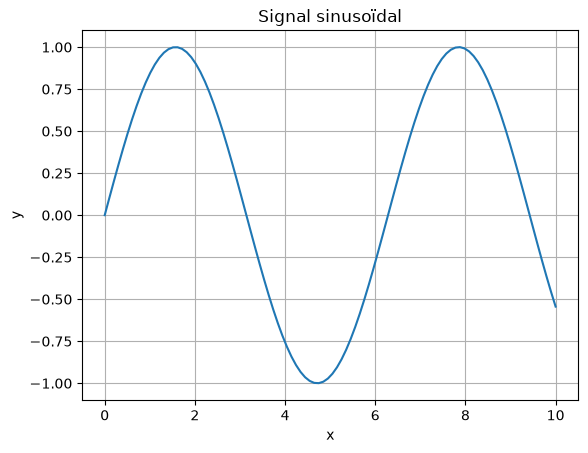

In [2]:
import matplotlib.pyplot as plt
import numpy as np

periode = np.linspace(0, 10, 100)
serie = np.sin(periode)

plt.plot(periode, serie)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Signal sinusoïdal")
plt.grid()
plt.show()